In [ ]:
import pandas as pd
import numpy as np

df = pd.read_csv(
    "../cardio_train.csv",
    sep=";"
) 
#Age in days, so divide by 365 to get years (roughly 30 to 65)
#gender (1 = women, 2 = men)
#height in cm
#weight in kg
#choles (1 = normal, 2 = above normal, 3 = well above normal) 
#Glucose, same 1 to 3 scale
# smoke (0 = no, 1 = yes)
#Alcohol intake, 0 = no, 1 = yes
#Physical activity, 0 = no, 1 = yes
#Target: 0 = no cardiovascular disease, 1 = has it


print(df.shape)
df.head()

(70000, 13)


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0


In [11]:
print(df.info())
print(df.describe())

<class 'pandas.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           70000 non-null  int64  
 1   age          70000 non-null  int64  
 2   gender       70000 non-null  int64  
 3   height       70000 non-null  int64  
 4   weight       70000 non-null  float64
 5   ap_hi        70000 non-null  int64  
 6   ap_lo        70000 non-null  int64  
 7   cholesterol  70000 non-null  int64  
 8   gluc         70000 non-null  int64  
 9   smoke        70000 non-null  int64  
 10  alco         70000 non-null  int64  
 11  active       70000 non-null  int64  
 12  cardio       70000 non-null  int64  
dtypes: float64(1), int64(12)
memory usage: 6.9 MB
None
                 id           age        gender        height        weight  \
count  70000.000000  70000.000000  70000.000000  70000.000000  70000.000000   
mean   49972.419900  19468.865814      1.349571    164.359

In [ ]:
print(df.dtypes)

print(df.nunique()) #affiche le nombre de valeurs distinctes

id               int64
age              int64
gender           int64
height           int64
weight         float64
ap_hi            int64
ap_lo            int64
cholesterol      int64
gluc             int64
smoke            int64
alco             int64
active           int64
cardio           int64
dtype: object
id             70000
age             8076
gender             2
height           109
weight           287
ap_hi            153
ap_lo            157
cholesterol        3
gluc               3
smoke              2
alco               2
active             2
cardio             2
dtype: int64


In [13]:
print(df["gender"].value_counts())
print(df["cholesterol"].value_counts())
print(df["gluc"].value_counts())
print(df["cardio"].value_counts())

gender
1    45530
2    24470
Name: count, dtype: int64
cholesterol
1    52385
2     9549
3     8066
Name: count, dtype: int64
gluc
1    59479
3     5331
2     5190
Name: count, dtype: int64
cardio
0    35021
1    34979
Name: count, dtype: int64


In [14]:
print(df.isnull().sum())

id             0
age            0
gender         0
height         0
weight         0
ap_hi          0
ap_lo          0
cholesterol    0
gluc           0
smoke          0
alco           0
active         0
cardio         0
dtype: int64


In [15]:
print("Duplicates:", df.duplicated().sum())

Duplicates: 0


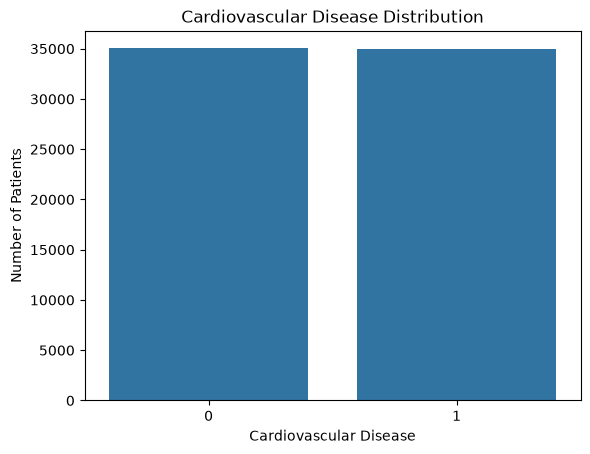

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(
    data=df,
    x="cardio"
)

plt.title("Cardiovascular Disease Distribution")
plt.xlabel("Cardiovascular Disease")
plt.ylabel("Number of Patients")

plt.show()

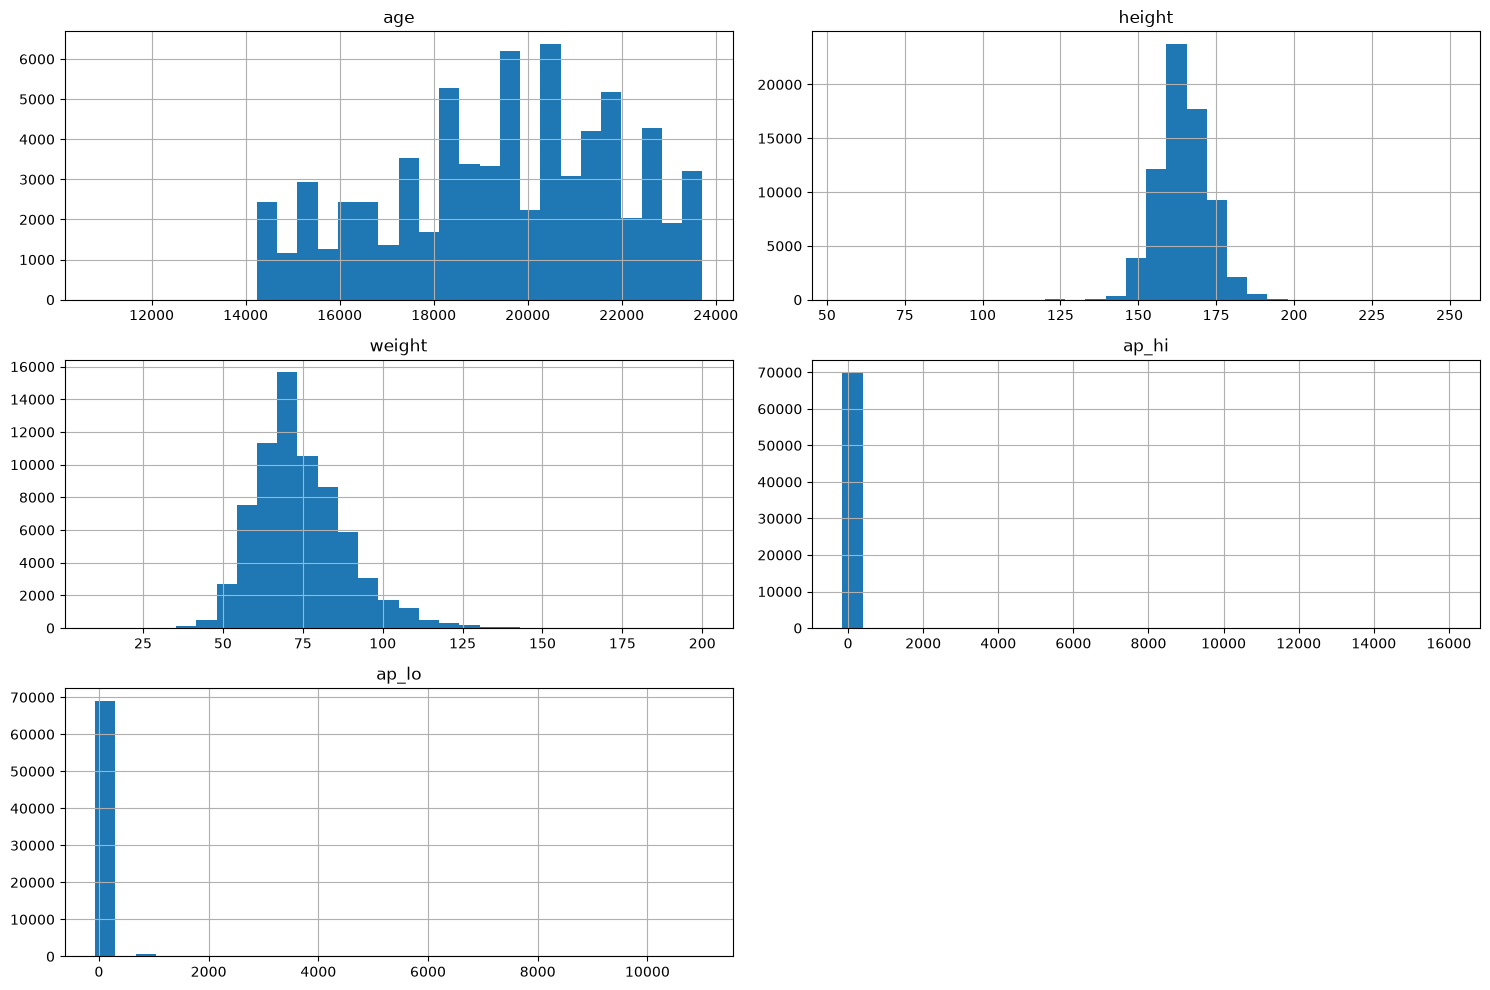

In [19]:
numerical_columns = [
    "age",
    "height",
    "weight",
    "ap_hi",
    "ap_lo"
]

df[numerical_columns].hist(
    figsize=(15, 10),
    bins=30
)

plt.tight_layout()
plt.show()

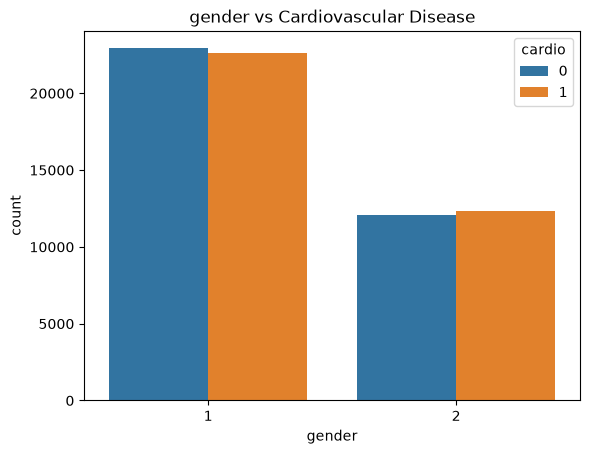

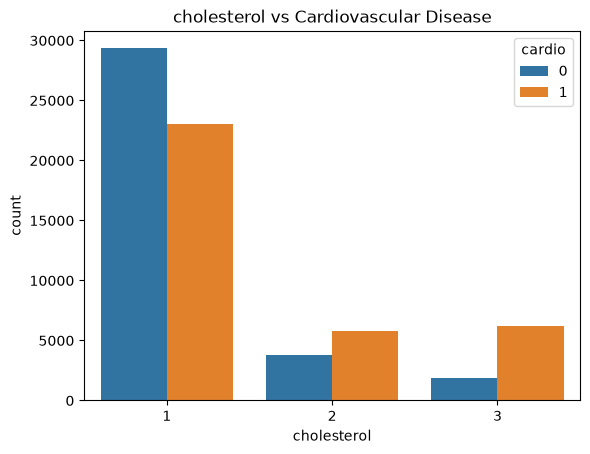

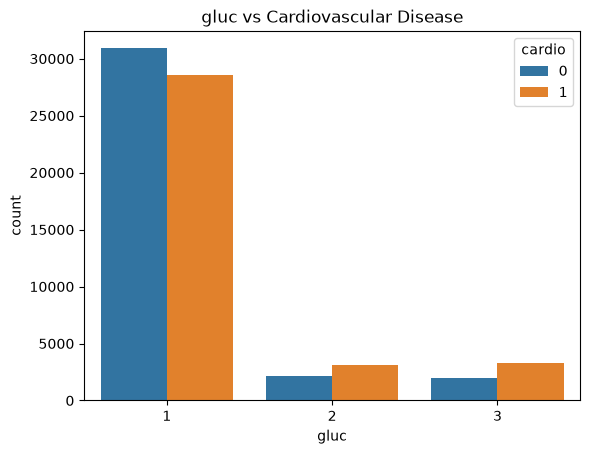

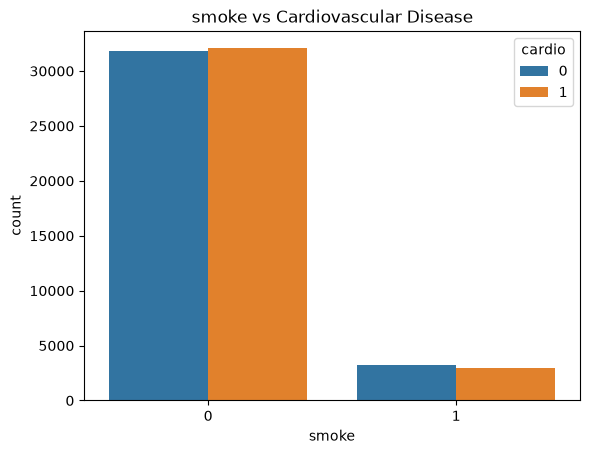

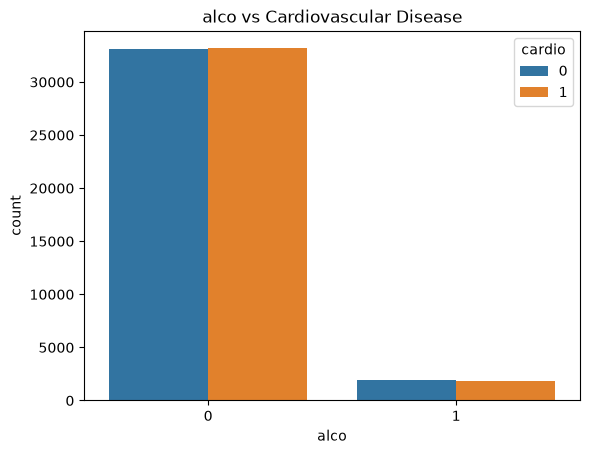

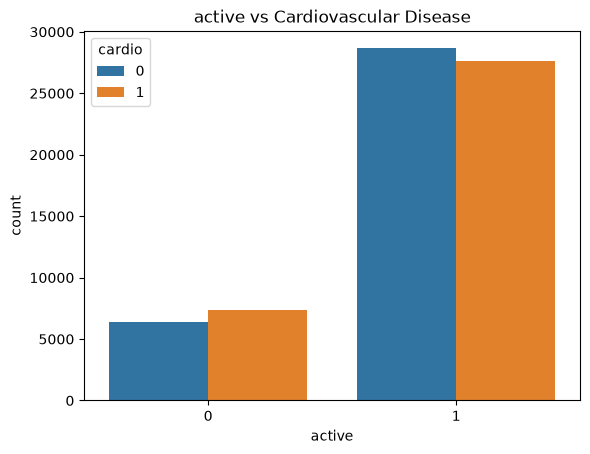

In [20]:
categorical_columns = [
    "gender",
    "cholesterol",
    "gluc",
    "smoke",
    "alco",
    "active"
]

for col in categorical_columns:

    sns.countplot(
        data=df,
        x=col,
        hue="cardio"
    )

    plt.title(f"{col} vs Cardiovascular Disease")
    plt.show()

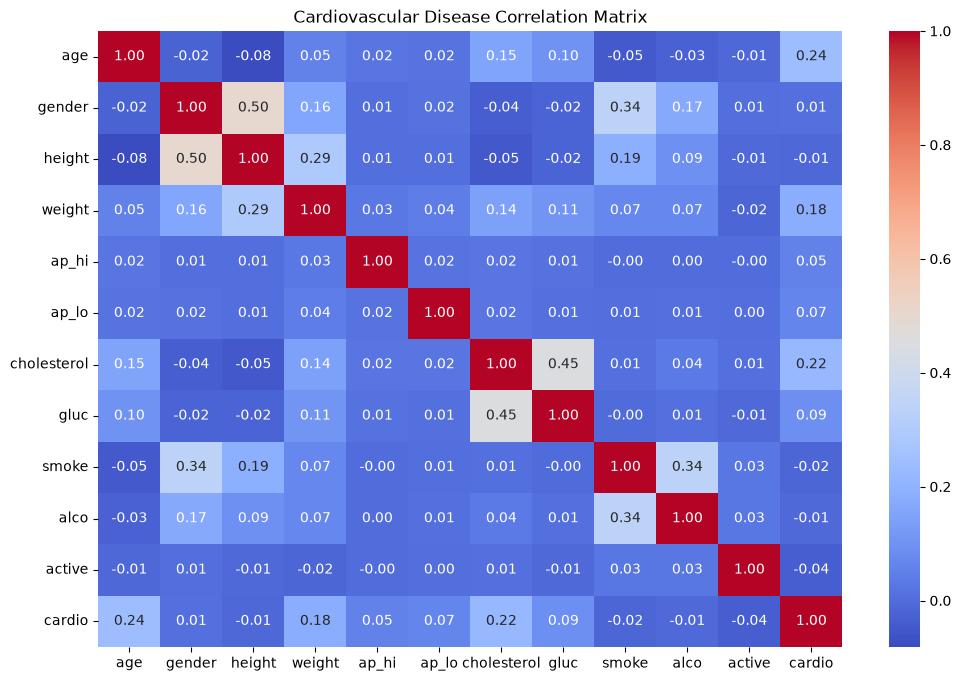

In [21]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    df.drop(columns=["id"]).corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Cardiovascular Disease Correlation Matrix")

plt.show()